In [167]:
import numpy as np
import pandas as pd
import warnings
from sklearn.preprocessing import OrdinalEncoder,OneHotEncoder
from sklearn.impute import KNNImputer
warnings.filterwarnings('ignore')

In [168]:
transport_df=pd.read_csv("commuter_transport.csv")

In [169]:
transport_df

,trip_id,trip_distance_km,trip_distance_miles,trip_duration_min,travel_cost_inr,walking_distance_m,departure_hour,traffic_level,transport_mode
0,1,15.50,9.63,103.8,35.86,899.2,14.0,3,Bus
1,2,15.77,9.80,62.8,311.66,27.8,11.0,2,Car
2,3,2.62,1.63,14.0,33.24,74.1,15.0,3,Two_Wheeler
3,4,8.42,5.23,25.5,60.26,99.1,23.0,2,Two_Wheeler
4,5,21.40,13.30,54.4,46.93,309.7,18.0,3,Metro
...,...,...,...,...,...,...,...,...,...
995,996,5.58,3.47,33.1,66.15,1372.5,2.0,1,Metro
996,997,12.27,7.62,54.1,244.61,104.0,19.0,1,Car
997,998,14.49,9.00,39.4,35.50,1264.2,22.0,2,Metro
998,999,22.69,14.10,99.0,394.70,121.1,3.0,3,Car


In [170]:
transport_df.head(5)

,trip_id,trip_distance_km,trip_distance_miles,trip_duration_min,travel_cost_inr,walking_distance_m,departure_hour,traffic_level,transport_mode
0,1,15.50,9.63,103.8,35.86,899.2,14.0,3,Bus
1,2,15.77,9.80,62.8,311.66,27.8,11.0,2,Car
2,3,2.62,1.63,14.0,33.24,74.1,15.0,3,Two_Wheeler
3,4,8.42,5.23,25.5,60.26,99.1,23.0,2,Two_Wheeler
4,5,21.40,13.30,54.4,46.93,309.7,18.0,3,Metro


In [171]:
transport_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   trip_id              1000 non-null   int64  
 1   trip_distance_km     990 non-null    float64
 2   trip_distance_miles  990 non-null    float64
 3   trip_duration_min    985 non-null    float64
 4   travel_cost_inr      985 non-null    float64
 5   walking_distance_m   985 non-null    float64
 6   departure_hour       990 non-null    float64
 7   traffic_level        1000 non-null   int64  
 8   transport_mode       1000 non-null   str    
dtypes: float64(6), int64(2), str(1)
memory usage: 70.4 KB


In [172]:
transport_df.describe()

,trip_id,trip_distance_km,trip_distance_miles,trip_duration_min,travel_cost_inr,walking_distance_m,departure_hour,traffic_level
count,1000.000000,990.000000,990.000000,985.000000,985.000000,985.000000,990.000000,1000.000000
mean,501.071000,12.138384,7.542556,49.303878,111.777330,515.411574,11.330303,1.993000
std,288.733214,6.694261,4.159698,32.205772,204.887426,1249.357428,6.908984,0.841224
min,1.000000,-5.000000,-3.110000,5.000000,-100.000000,0.200000,0.000000,1.000000
25%,251.750000,7.077500,4.395000,28.600000,33.230000,66.700000,5.000000,1.000000
50%,501.500000,11.830000,7.350000,44.300000,52.690000,185.200000,11.000000,2.000000
75%,751.250000,16.720000,10.392500,63.100000,80.360000,713.900000,17.000000,3.000000
max,1000.000000,49.350000,30.660000,300.000000,2955.950000,15000.000000,25.000000,5.000000


In [173]:
transport_df.describe(include="all")

,trip_id,trip_distance_km,trip_distance_miles,trip_duration_min,travel_cost_inr,walking_distance_m,departure_hour,traffic_level,transport_mode
count,1000.000000,990.000000,990.000000,985.000000,985.000000,985.000000,990.000000,1000.000000,1000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Metro
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,271
mean,501.071000,12.138384,7.542556,49.303878,111.777330,515.411574,11.330303,1.993000,NaN
std,288.733214,6.694261,4.159698,32.205772,204.887426,1249.357428,6.908984,0.841224,NaN
min,1.000000,-5.000000,-3.110000,5.000000,-100.000000,0.200000,0.000000,1.000000,NaN
25%,251.750000,7.077500,4.395000,28.600000,33.230000,66.700000,5.000000,1.000000,NaN
50%,501.500000,11.830000,7.350000,44.300000,52.690000,185.200000,11.000000,2.000000,NaN
75%,751.250000,16.720000,10.392500,63.100000,80.360000,713.900000,17.000000,3.000000,NaN


In [174]:
transport_df.isnull().sum()

trip_id                 0
trip_distance_km       10
trip_distance_miles    10
trip_duration_min      15
travel_cost_inr        15
walking_distance_m     15
departure_hour         10
traffic_level           0
transport_mode          0
dtype: int64

In [175]:
import math 
transport=math.floor(transport_df.trip_distance_km.median())

In [176]:
transport

11

In [177]:
transport_df.trip_distance_km=transport_df.trip_distance_km.fillna(transport)

In [178]:
transport_df.trip_distance_km.isnull().sum()

np.int64(0)

In [179]:
duration=math.floor(transport_df.trip_duration_min.median())

In [180]:
duration

44

In [181]:
transport_df.trip_duration_min=transport_df.trip_duration_min.fillna(duration)

In [182]:
transport_df=transport_df.fillna(transport_df.median(numeric_only=True))

In [183]:
transport_df.isnull().sum()

trip_id                0
trip_distance_km       0
trip_distance_miles    0
trip_duration_min      0
travel_cost_inr        0
walking_distance_m     0
departure_hour         0
traffic_level          0
transport_mode         0
dtype: int64

In [184]:
encoder=OrdinalEncoder()
transport_df[['transport_mode']]=encoder.fit_transform(transport_df[['transport_mode']])

In [185]:
transport_df['transport_mode'].head()

0    0.0
1    1.0
2    3.0
3    3.0
4    2.0
Name: transport_mode, dtype: float64

In [186]:
transport_df

,trip_id,trip_distance_km,trip_distance_miles,trip_duration_min,travel_cost_inr,walking_distance_m,departure_hour,traffic_level,transport_mode
0,1,15.50,9.63,103.8,35.86,899.2,14.0,3,0.0
1,2,15.77,9.80,62.8,311.66,27.8,11.0,2,1.0
2,3,2.62,1.63,14.0,33.24,74.1,15.0,3,3.0
3,4,8.42,5.23,25.5,60.26,99.1,23.0,2,3.0
4,5,21.40,13.30,54.4,46.93,309.7,18.0,3,2.0
...,...,...,...,...,...,...,...,...,...
995,996,5.58,3.47,33.1,66.15,1372.5,2.0,1,2.0
996,997,12.27,7.62,54.1,244.61,104.0,19.0,1,1.0
997,998,14.49,9.00,39.4,35.50,1264.2,22.0,2,2.0
998,999,22.69,14.10,99.0,394.70,121.1,3.0,3,1.0


In [187]:
transport_df.head()

,trip_id,trip_distance_km,trip_distance_miles,trip_duration_min,travel_cost_inr,walking_distance_m,departure_hour,traffic_level,transport_mode
0,1,15.50,9.63,103.8,35.86,899.2,14.0,3,0.0
1,2,15.77,9.80,62.8,311.66,27.8,11.0,2,1.0
2,3,2.62,1.63,14.0,33.24,74.1,15.0,3,3.0
3,4,8.42,5.23,25.5,60.26,99.1,23.0,2,3.0
4,5,21.40,13.30,54.4,46.93,309.7,18.0,3,2.0


transport_mode
2.0    271
3.0    253
1.0    243
0.0    233
Name: count, dtype: int64


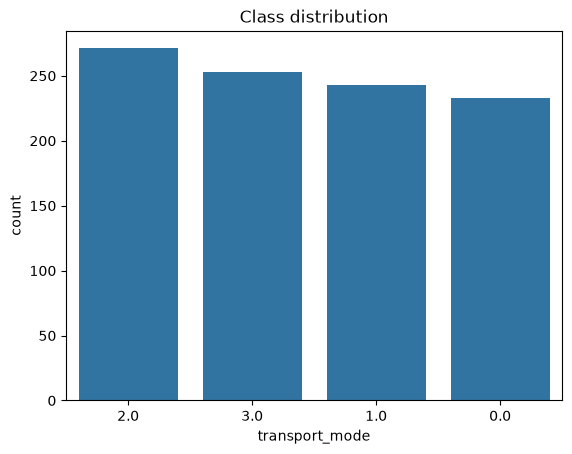

In [188]:

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, f1_score)

RANDOM_STATE = 42

#quick EDA
#Bar plot
print(transport_df["transport_mode"].value_counts())
sns.countplot(data=transport_df, x="transport_mode", order=transport_df["transport_mode"].value_counts().index)
plt.title("Class distribution")
plt.show()

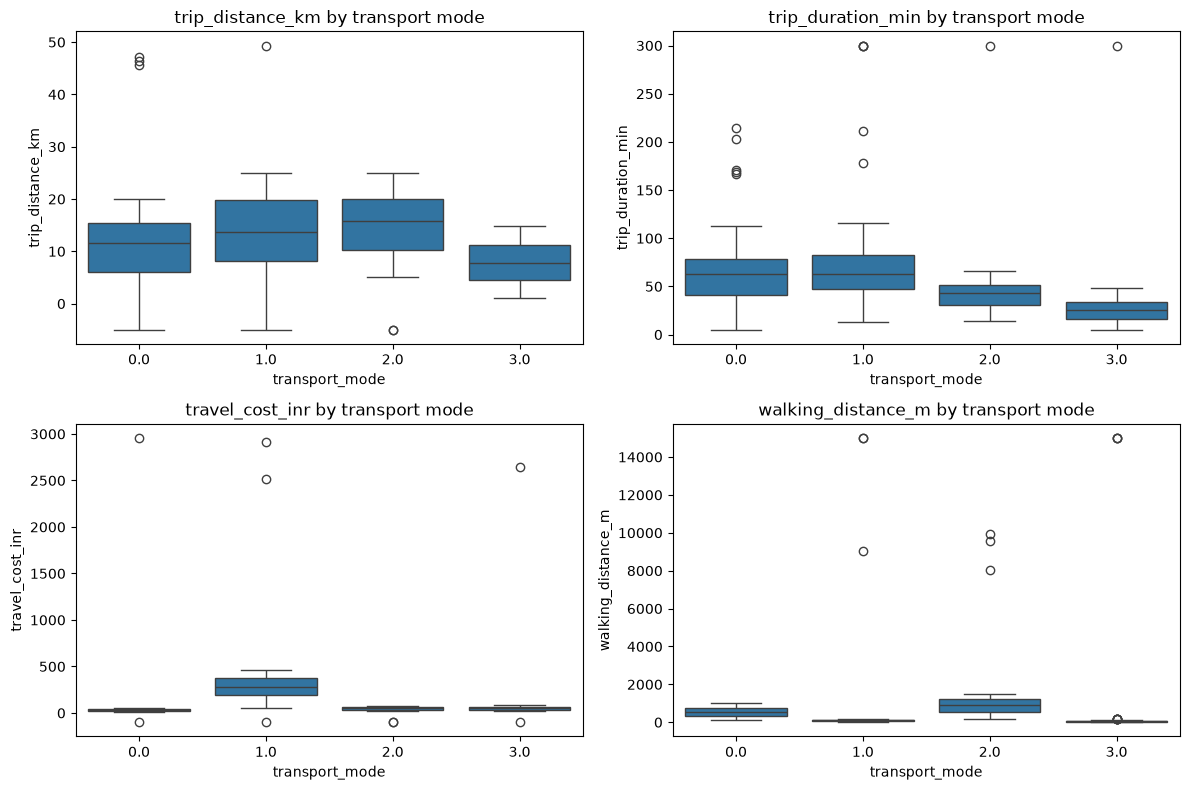

In [189]:
#box graph
num_cols = ["trip_distance_km", "trip_duration_min", "travel_cost_inr", "walking_distance_m"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(data=transport_df, x="transport_mode", y=col, ax=ax)
    ax.set_title(f"{col} by transport mode")
plt.tight_layout()
plt.show()

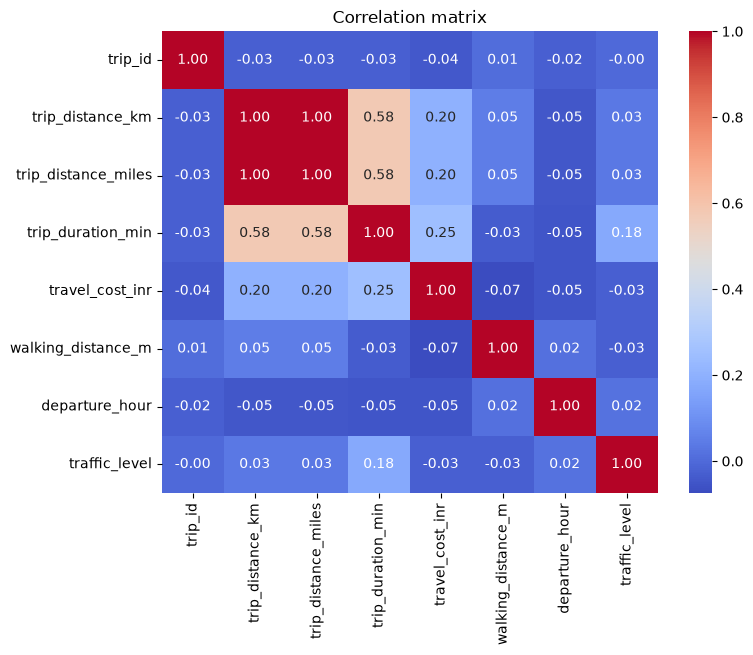

In [190]:
#correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(transport_df.drop(columns=["transport_mode"]).corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix")
plt.show()

In [191]:
drop_cols = [c for c in ["trip_id", "trip_distance_miles"] if c in transport_df.columns]
X = transport_df.drop(columns=drop_cols + ["transport_mode"])
y = transport_df["transport_mode"]

print("Features used:", list(X.columns))

Features used: ['trip_distance_km', 'trip_duration_min', 'travel_cost_inr', 'walking_distance_m', 'departure_hour', 'traffic_level']


In [192]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (800, 6)  Test: (200, 6)


In [193]:
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
base_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
print(f"Baseline (k=5) CV accuracy: {base_scores.mean():.4f} ± {base_scores.std():.4f}")

Baseline (k=5) CV accuracy: 0.8688 ± 0.0253


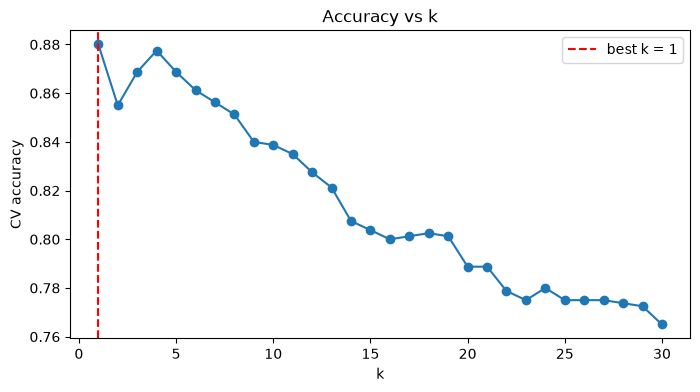

Best k: 1 | CV accuracy: 0.88


In [194]:
k_values = range(1, 31)
cv_means = []
for k in k_values:
    p = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=k))])
    cv_means.append(cross_val_score(p, X_train, y_train, cv=cv, scoring="accuracy").mean())

best_k = list(k_values)[int(np.argmax(cv_means))]
plt.figure(figsize=(8, 4))
plt.plot(list(k_values), cv_means, marker="o")
plt.axvline(best_k, color="red", ls="--", label=f"best k = {best_k}")
plt.xlabel("k"); plt.ylabel("CV accuracy"); plt.title("Accuracy vs k"); plt.legend()
plt.show()
print("Best k:", best_k, "| CV accuracy:", round(max(cv_means), 4))

In [195]:
param_grid = {
    "knn__n_neighbors": list(range(3, 26, 2)),
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],            # 1 = Manhattan, 2 = Euclidean
}

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1_macro", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best params :", grid.best_params_)
print("Best CV macro-F1:", round(grid.best_score_, 4))

Best params : {'knn__n_neighbors': 3, 'knn__p': 1, 'knn__weights': 'distance'}
Best CV macro-F1: 0.902


In [196]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print("Test accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Test macro-F1 :", round(f1_score(y_test, y_pred, average="macro"), 4))
print()
print(classification_report(y_test, y_pred))

Test accuracy : 0.915
Test macro-F1 : 0.9155

              precision    recall  f1-score   support

         0.0       0.84      0.93      0.89        46
         1.0       0.98      0.92      0.95        49
         2.0       1.00      0.87      0.93        54
         3.0       0.86      0.94      0.90        51

    accuracy                           0.92       200
   macro avg       0.92      0.92      0.92       200
weighted avg       0.92      0.92      0.92       200



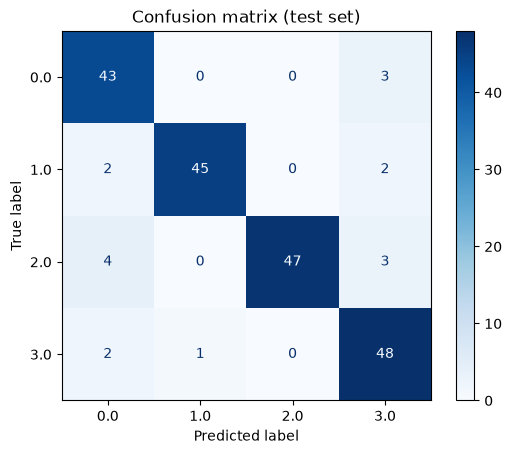

In [197]:
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix (test set)")
plt.show()

In [198]:
sample = pd.DataFrame([{
    "trip_distance_km": 12.0,
    "trip_duration_min": 40.0,
    "travel_cost_inr": 45.0,
    "walking_distance_m": 600.0,
    "departure_hour": 9,
    "traffic_level": 2,
}])[X.columns]

print("Predicted mode:", best_model.predict(sample)[0])
print(dict(zip(best_model.classes_, best_model.predict_proba(sample)[0].round(3))))

Predicted mode: 2.0
{np.float64(0.0): np.float64(0.0), np.float64(1.0): np.float64(0.0), np.float64(2.0): np.float64(0.739), np.float64(3.0): np.float64(0.261)}


In [199]:
# Example: predict the transport mode for 4 new trips
new_trips = pd.DataFrame([
    # distance, duration, cost, walking, hour, traffic
    dict(trip_distance_km=3.0,  trip_duration_min=12,  travel_cost_inr=25,  walking_distance_m=40,  departure_hour=15, traffic_level=2),
    dict(trip_distance_km=16.0, trip_duration_min=60,  travel_cost_inr=300, walking_distance_m=25,  departure_hour=11, traffic_level=2),
    dict(trip_distance_km=20.0, trip_duration_min=55,  travel_cost_inr=45,  walking_distance_m=300, departure_hour=18, traffic_level=3),
    dict(trip_distance_km=15.0, trip_duration_min=100, travel_cost_inr=35,  walking_distance_m=900, departure_hour=14, traffic_level=3),
])[X.columns]   # keeps the columns in the same order as training

predictions = best_model.predict(new_trips)
probabilities = pd.DataFrame(best_model.predict_proba(new_trips),
                             columns=best_model.classes_).round(2)

result = new_trips.copy()
result["predicted_mode"] = predictions
display(result)
display(probabilities)

,trip_distance_km,trip_duration_min,travel_cost_inr,walking_distance_m,departure_hour,traffic_level,predicted_mode
0,3.0,12,25,40,15,2,3.0
1,16.0,60,300,25,11,2,1.0
2,20.0,55,45,300,18,3,2.0
3,15.0,100,35,900,14,3,0.0


,0.0,1.0,2.0,3.0
0,0.0,0.0,0.0,1.0
1,0.0,1.0,0.0,0.0
2,0.0,0.0,1.0,0.0
3,1.0,0.0,0.0,0.0
